In [1]:
import ffdi_variables_analysis as fva
import matplotlib.pyplot as plt
import pandas as pd
import math
import glob
import os
import seaborn as sns

In [2]:
n=300
iterations=100
setno=1
df = fva.sample_and_varimp(nsamp=n, set=setno, iterations=iterations)
df.to_csv('variable_importance_set1.csv', index=False)

In [3]:
df['varianceby299'] = (n-1) * df['importances_std'] * df['importances_std']

# Now, aggregate varianceby299 by Variable, country, and gwl
denom = (n * iterations) - iterations

# variances = df.groupby(['Variable', 'country', 'gwl']).sum('varianceby299').reset_index()
varimp_pooled = df.groupby(['Variable', 'Variable_nice', 'country', 'gwl']).agg({'importances': 'mean', 'varianceby299': 'sum'}).reset_index()

varimp_pooled['importances_std'] = (varimp_pooled['varianceby299'] / denom).apply(math.sqrt)

varimp_pooled.to_csv('variable_importances_pooled.csv', index=False)

In [4]:
print(varimp_pooled.loc[varimp_pooled['gwl'] == 'Baseline'])

                           Variable Variable_nice                   country  \
0                   air_temperature             T                 Australia   
2                   air_temperature             T                    Brazil   
4                   air_temperature             T  United States of America   
6          precipitation_in_mpersec            Pr                 Australia   
8          precipitation_in_mpersec            Pr                    Brazil   
10         precipitation_in_mpersec            Pr  United States of America   
12                relative_humidity            RH                 Australia   
14                relative_humidity            RH                    Brazil   
16                relative_humidity            RH  United States of America   
18  soil_moisture_content_top_metre            SM                 Australia   
20  soil_moisture_content_top_metre            SM                    Brazil   
22  soil_moisture_content_top_metre            SM  U

Text(0.5, 0, '')

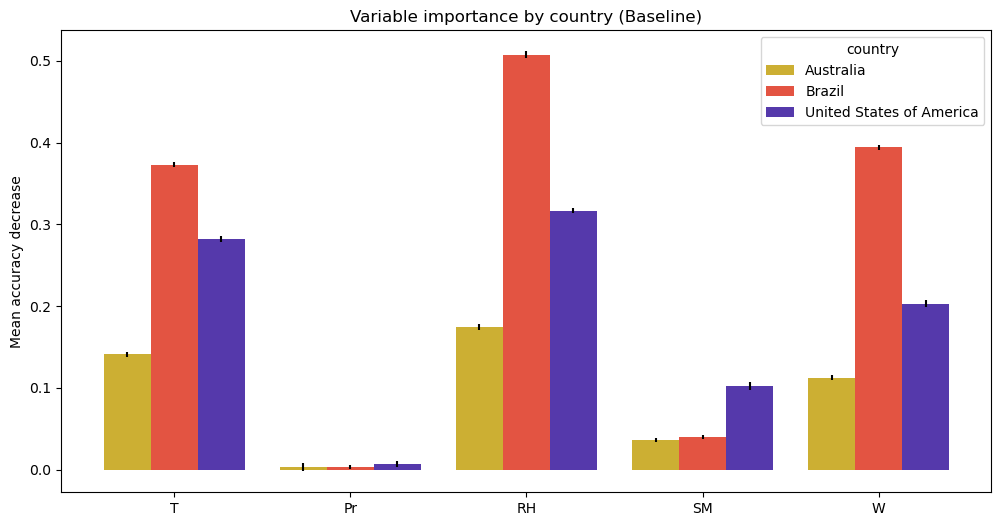

In [5]:
ni = 3

varimp_ss = varimp_pooled.loc[varimp_pooled['gwl'] == 'Baseline']

fig = plt.figure(figsize=(12, 6))
ax = sns.barplot(data=varimp_ss, x='Variable_nice', y='importances', hue='country', palette='CMRmap_r')
# Do something with error bars
# Based on https://stackoverflow.com/questions/72352491/how-to-plot-errorbars-on-seaborn-barplot
x_coords = [p.get_x() + 0.5 * p.get_width() for p in ax.patches]
y_coords = [p.get_height() for p in ax.patches]
ax.errorbar(x=x_coords[:-ni], y=y_coords[:-ni], yerr=varimp_ss["importances_std"], fmt="none", c="k")

ax.set_title("Variable importance by country (Baseline)")
ax.set_ylabel("Mean accuracy decrease")
ax.set_xlabel("")
# plt.savefig(f'/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers_variable_importance_3countries_allGWLs-Stratification.png')

AttributeError: 'FacetGrid' object has no attribute 'errorbar'

<Figure size 1200x600 with 0 Axes>

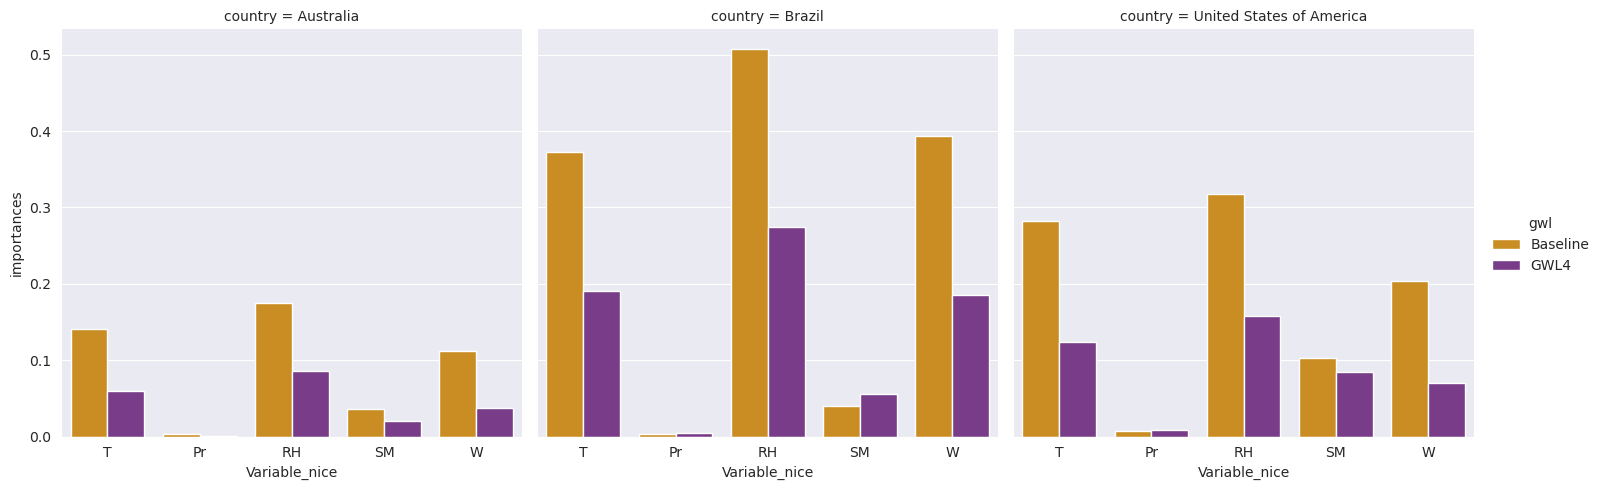

In [38]:
fig = plt.figure(figsize=(12, 6))
ax = sns.catplot(varimp_pooled, kind="bar", x="Variable_nice", y="importances", col="country", hue="gwl", palette='CMRmap_r')

# x_coords = [p.get_x() + 0.5 * p.get_width() for p in ax.patches]
# y_coords = [p.get_height() for p in ax.patches]
ax.errorbar(x=x_coords[:-ni], y=y_coords[:-ni], yerr=varimp_pooled["importances_std"], fmt="none", c="k")

ax.set_title("Variable importance by country (Baseline vs 4°C GWL)")
ax.set_ylabel("Mean accuracy decrease")
ax.set_xlabel("")
plt.savefig(f'/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers_variable_importance_3countries_samp{n}_iterations{iterations}_set{setno}.png')

In [6]:
df

,Unnamed: 0,Variable,importances,importances_std,country,gwl,Variable_nice,varianceby299
0,0,air_temperature,0.141727,0.002276,Australia,Baseline,T,0.001548
1,1,precipitation_in_mpersec,0.006428,0.002497,Australia,Baseline,Pr,0.001864
2,2,relative_humidity,0.177729,0.002586,Australia,Baseline,RH,0.001999
3,3,soil_moisture_content_top_metre,0.041328,0.003257,Australia,Baseline,SM,0.003171
4,4,windspeed_in_km_per_hr,0.115291,0.004172,Australia,Baseline,W,0.005204
...,...,...,...,...,...,...,...,...
25,25,air_temperature,0.129978,0.004947,United States of America,GWL4,T,0.007319
26,26,precipitation_in_mpersec,0.013444,0.003566,United States of America,GWL4,Pr,0.003803
27,27,relative_humidity,0.166571,0.004205,United States of America,GWL4,RH,0.005287
28,28,soil_moisture_content_top_metre,0.088497,0.006724,United States of America,GWL4,SM,0.013520


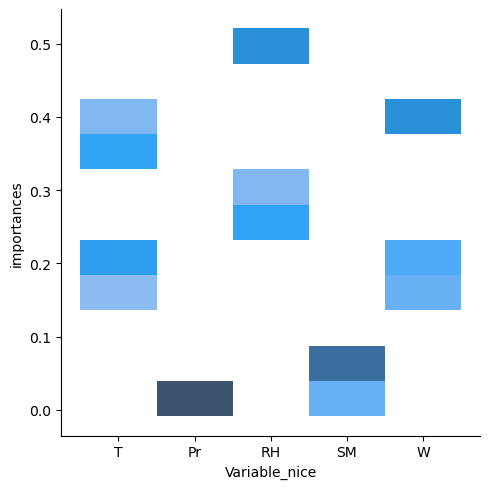

In [7]:
sns.displot(df.loc[df['country'] == 'Brazil'], x='Variable_nice', y='importances')

In [9]:
import seaborn.objects as so

In [ ]:
(
    so.Plot(df, x="species", y="body_mass_g", color="sex")
    .add(so.Dot(pointsize=10), so.Agg())
)
